<a href="https://colab.research.google.com/github/LuizHRPereira/estudos_ciencia_de_dados_com_python/blob/main/02-projeto-analise-engajamento-instagram/analise_engajamento_instagram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iniciando com a importação do pandas e base de dados

In [95]:
import pandas as pd
import numpy as np

base = pd.read_excel('08. Analisando o engajamento no Instagram.xlsx')

visualizando a primeiras linha

In [96]:
base.head()

,Tipo,Data,Curtidas,Comentários,Visualizações,Tags,Pessoas,Campanhas,Carrossel,Interacoes
0,Foto,2021-09-11,2858,16,NaN,Loja,N,N,NaN,2874
1,Foto,2021-09-11,2930,28,NaN,Loja/Produtos,N,N,NaN,2958
2,Foto,2021-09-11,2807,9,NaN,Loja,N,N,NaN,2816
3,Vídeo,2021-09-12,5115,49,"82,878.00",Produtos,N,N,NaN,5164
4,Foto,2021-09-13,4392,45,NaN,Produtos,S,N,NaN,4437


apagando a coluna de 'Visualizações'

""no cenário proposto a coluna em questão foi citada para desconsiderar""

In [97]:
base = base.drop('Visualizações', axis=1)

verificando o tamnho da base

In [98]:
base.shape

(52, 9)

verificar as informações da base

In [99]:
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Tipo         52 non-null     object        
 1   Data         52 non-null     datetime64[ns]
 2   Curtidas     52 non-null     int64         
 3   Comentários  52 non-null     int64         
 4   Tags         44 non-null     object        
 5   Pessoas      52 non-null     object        
 6   Campanhas    52 non-null     object        
 7   Carrossel    8 non-null      object        
 8   Interacoes   52 non-null     int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 3.8+ KB


Em uma base de dados retirada do instagram a coluna Carrosel identifica o tipo do formato da publicação que contém múltiplas mídias
verificando os valores nulos na coluna Carrosel

In [100]:
base.Carrossel.value_counts()

,count
Carrossel,
S,8


filtrando os valroes nulos da coluna Carrosel

In [101]:
base.loc[base.Carrossel.isnull()]

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
0,Foto,2021-09-11,2858,16,Loja,N,N,NaN,2874
1,Foto,2021-09-11,2930,28,Loja/Produtos,N,N,NaN,2958
2,Foto,2021-09-11,2807,9,Loja,N,N,NaN,2816
3,Vídeo,2021-09-12,5115,49,Produtos,N,N,NaN,5164
4,Foto,2021-09-13,4392,45,Produtos,S,N,NaN,4437
6,Foto,2021-09-19,21597,852,Novos Produtos,S,S,NaN,22449
7,Foto,2021-09-25,6346,33,Produtos,N,S,NaN,6379
9,Vídeo,2021-09-28,4056,81,Produtos,N,N,NaN,4137
10,Reels,2021-10-10,12894,249,Trends/Produtos,S,N,NaN,13143
11,Foto,2021-10-12,17831,391,NaN,S,S,NaN,18222


Por entender que o nulo erpresenta as publicações que não são do tipo carrosel, o próximo passo é substituir o nulo por não ou "N"

In [102]:
base.loc[base.Carrossel.isnull(),"Carrossel"] = 'N'


verificando novamente a base de dados

In [103]:
base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Tipo         52 non-null     object        
 1   Data         52 non-null     datetime64[ns]
 2   Curtidas     52 non-null     int64         
 3   Comentários  52 non-null     int64         
 4   Tags         44 non-null     object        
 5   Pessoas      52 non-null     object        
 6   Campanhas    52 non-null     object        
 7   Carrossel    52 non-null     object        
 8   Interacoes   52 non-null     int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 3.8+ KB


alterando as linhas nulas da coluna tag para SEM_TAG,  a fim de padronizar a base de dados.

In [104]:
base.loc[base.Tags.isnull(), 'Tags'] = 'SEM/TAG'
base.Tags.value_counts()

,count
Tags,
Produtos,12
SEM/TAG,8
Novos Produtos,7
Influenciadores,7
Datas comemorativas,3
Dicas de como usar/Produtos,3
Trends,3
Loja,2
Promoções,2


começando a analisar as informações estatísticas com o describe

In [105]:
base.describe()

,Data,Curtidas,Comentários,Interacoes
count,52,52.00,52.00,52.00
mean,2021-12-23 04:36:55.384615424,"12,262.73",189.50,"12,452.23"
min,2021-09-11 00:00:00,"2,807.00",9.00,"2,816.00"
25%,2021-10-23 06:00:00,"5,492.00",69.50,"5,562.50"
50%,2022-01-05 00:00:00,"9,603.00",128.00,"9,773.50"
75%,2022-02-15 12:00:00,"17,621.75",265.25,"17,920.75"
max,2022-03-27 00:00:00,"37,351.00",852.00,"37,853.00"
std,NaN,"8,165.88",170.69,"8,299.39"


criar um gráfico de área com as curtidas em relação ao tempo

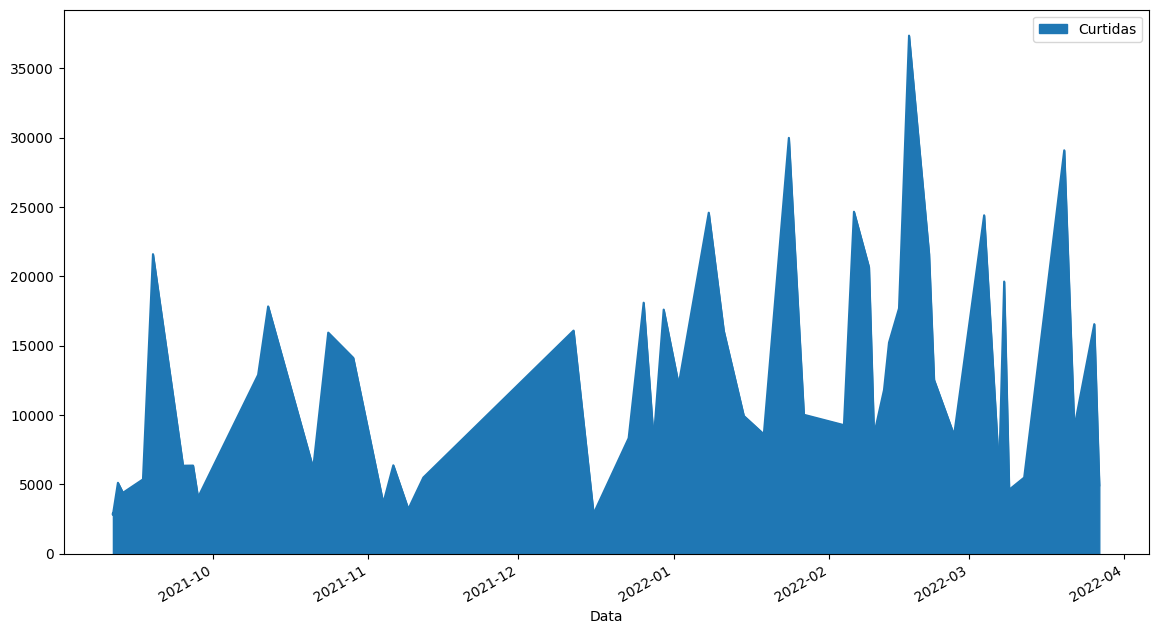

In [106]:
base.plot(kind='area', x='Data',y='Curtidas',figsize=(14,8));

ordenar os registros de acordo com o maior número de curtidas

ascending = false - oredena de forma decrescente
ascending = true - oredena de forma ascendetef

In [107]:
base.sort_values(by='Curtidas', ascending=False).head()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
39,Foto,2022-02-17,37351,502,Promoções,S,S,N,37853
30,Reels,2022-01-24,29981,502,Trends,S,S,N,30483
48,Foto,2022-03-20,29084,479,Datas comemorativas/Promoções,S,S,N,29563
33,Foto,2022-02-06,24655,186,Influenciadores,S,S,N,24841
26,Foto,2022-01-08,24585,354,Datas comemorativas,S,S,S,24939


agrupando informações de curtida por tipo de publicação

a prmeira linha é somente para formatar melhor o número

In [108]:
pd.options.display.float_format = '{:,.2f}'.format
base.groupby('Tipo')['Curtidas'].mean()

,Curtidas
Tipo,
Foto,"13,341.14"
IGTV,"6,833.40"
Reels,"14,873.00"
Vídeo,"8,141.50"


todas as publicações que tem número de curtida menor que a média

In [109]:
base.loc[base.Curtidas < base.Curtidas.mean(), ['Tipo', 'Curtidas','Data']]

,Tipo,Curtidas,Data
0,Foto,2858,2021-09-11
1,Foto,2930,2021-09-11
2,Foto,2807,2021-09-11
3,Vídeo,5115,2021-09-12
4,Foto,4392,2021-09-13
5,Foto,5359,2021-09-17
7,Foto,6346,2021-09-25
8,Foto,6355,2021-09-27
9,Vídeo,4056,2021-09-28
12,Foto,6166,2021-10-21


agregando a média do número de curtida e comentários por pessoas e campanha

In [115]:
base.groupby(['Pessoas','Campanhas'])[['Curtidas','Comentários']].mean()

Curtidas  Comentários
Pessoas Campanhas                       
N       N          3,937.50        53.90
        S          5,852.50        47.50
S       N          9,923.75       157.80
        S         19,405.35       303.20